# 3_Phase-1

## 10.26.26 | diversity of samples compared to controls

In [1]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(data.table)
    library(microbiome)
})
    
options(repr.plot.width=15, repr.plot.height=8)

In [3]:
ps_bacteria <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-dada2-rel-bacteria.rds")

In [4]:
# Subset phase 1 and control samples in new phyloseq object
ps_p1 <- subset_samples(ps_bacteria, Phase == 1 | Tissue %in% c("Negative_control", "Positive_control"))
ps_p1 <- prune_taxa(taxa_sums(ps_p1) > 0, ps_p1)
ps_p1

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 38946 taxa and 67 samples ]
sample_data() Sample Data:       [ 67 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 38946 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 38946 reference sequences ]

In [5]:
# Compute distance matrix
dist_bray <- phyloseq::distance(ps_p1, method = "bray")

In [6]:
# Ordinate using PCoA
ord_bray <- ordinate(ps_p1, method = "PCoA", distance = dist_bray)

# Variance explained by each axis
ord_bray$values$Relative_eig[1:5] %>% round(3)

[1] 0.194 0.112 0.064 0.055 0.053

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the phyloseq package.
  Please report the issue at <https://github.com/joey711/phyloseq/issues>.”


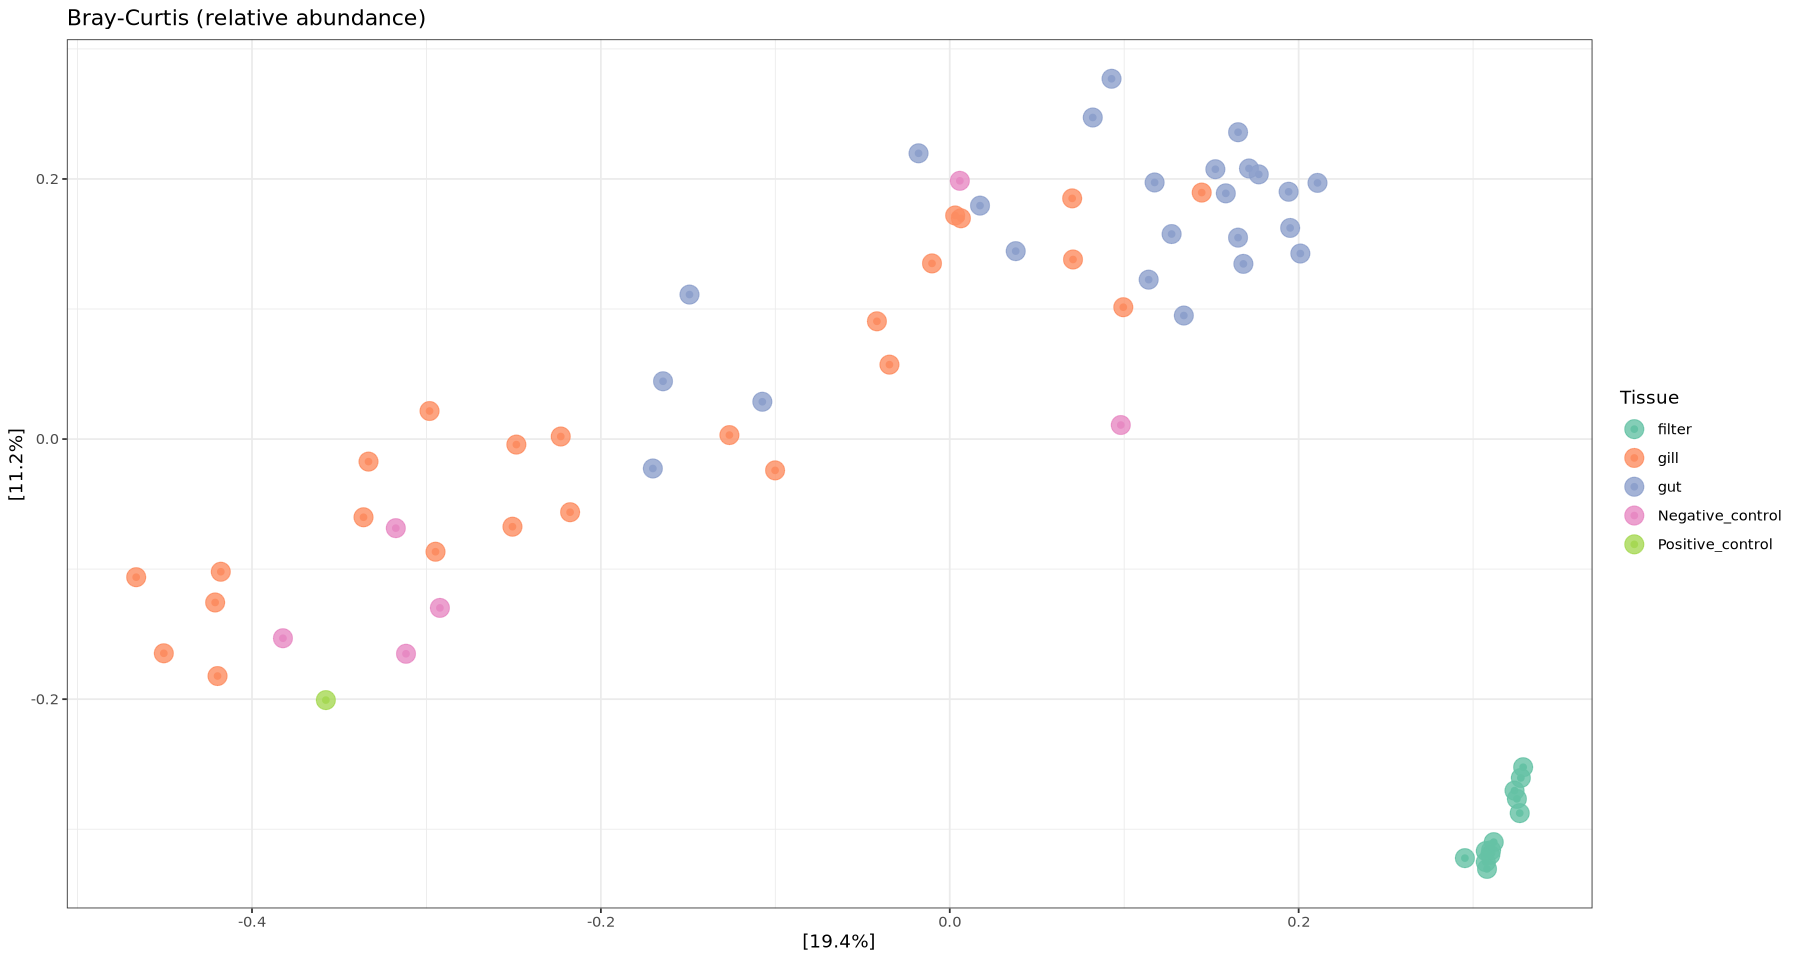

In [7]:
# Visualize PCoA
p_bray_p1 <- plot_ordination(ps_p1, ord_bray, color = "Tissue") +
    geom_point(size = 5, alpha = 0.8) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "Bray-Curtis (relative abundance)") +
    theme_bw()
p_bray_p1

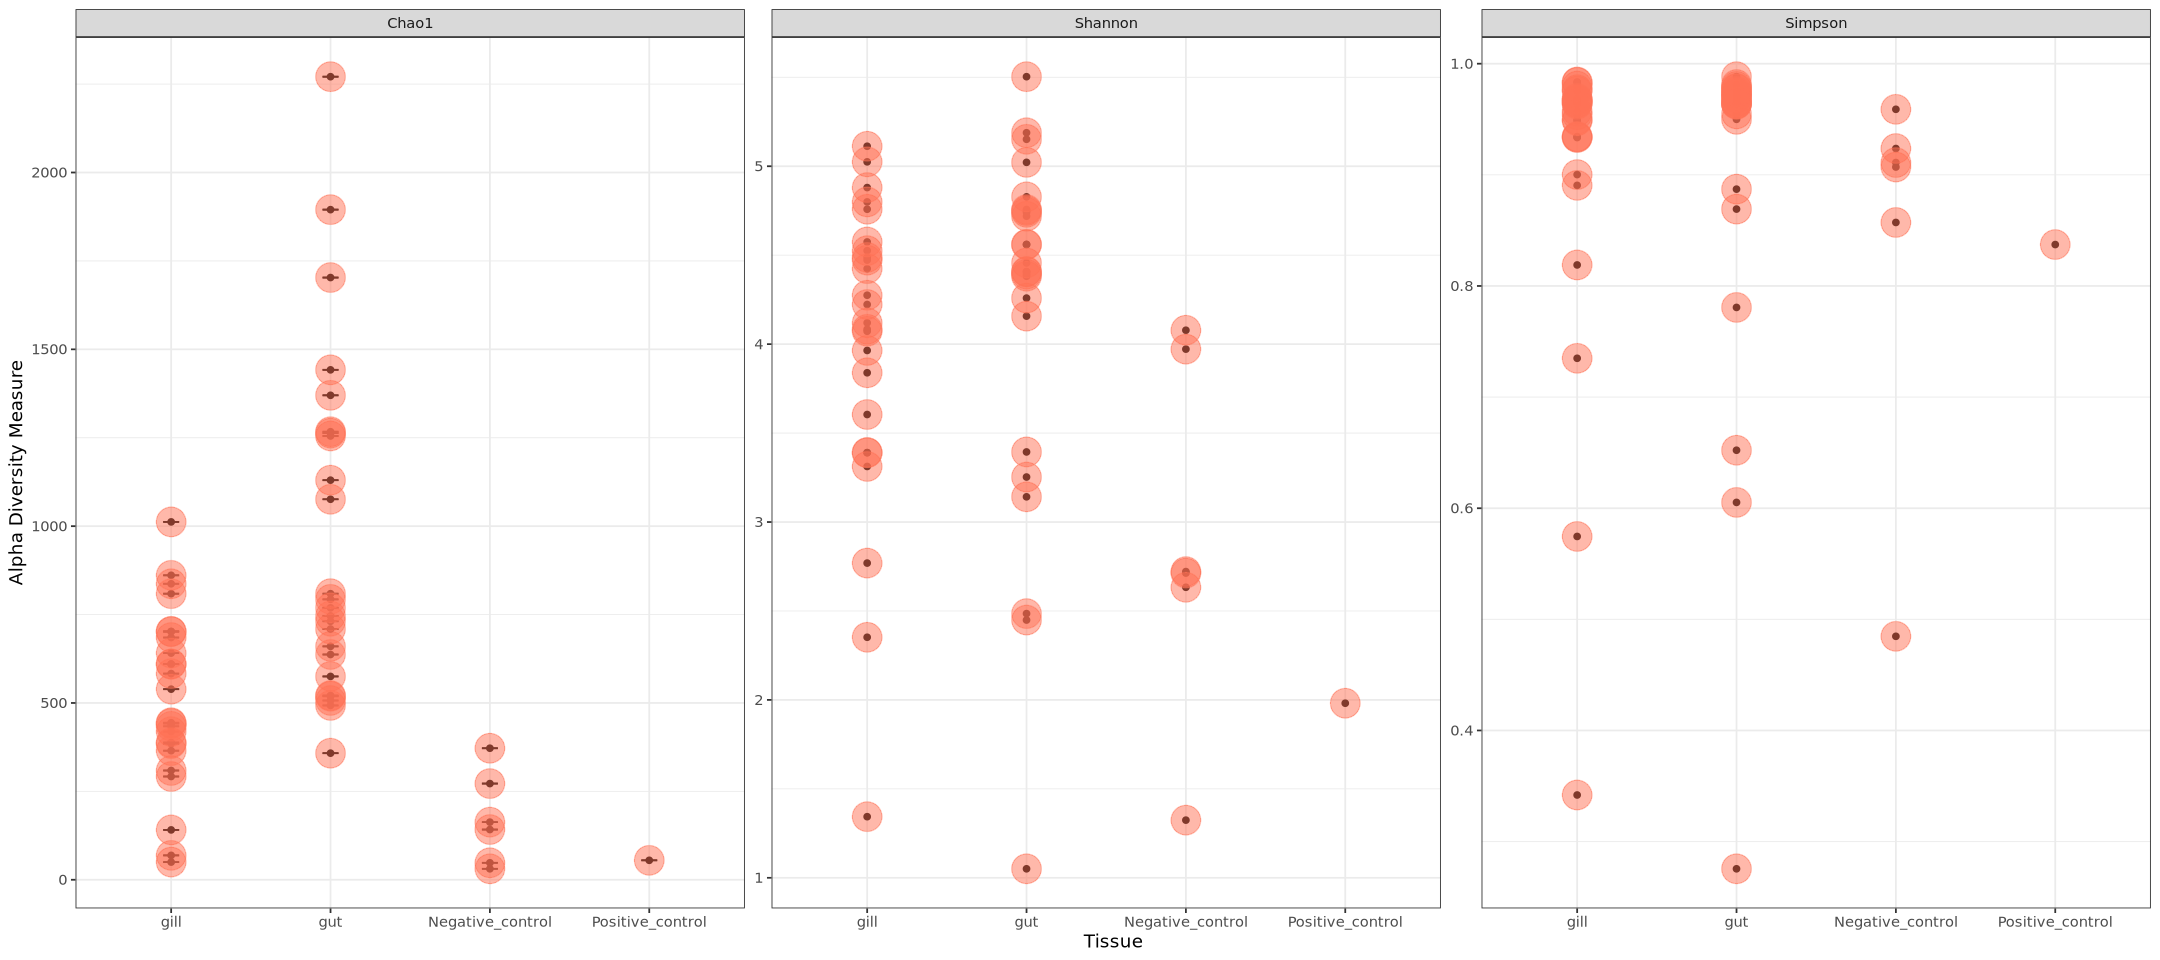

In [5]:
plot_richness(ps_p1, x = "Tissue", measures = c("Shannon", "Simpson", "Chao1")) +
    geom_point(size = 8, alpha = 0.5, color = "coral 1")  +
    theme_bw()